In [1]:
import pyC2C as c2c
import matplotlib.pyplot as plt
import pandas as pd

### Load source data and results data frame

In [ ]:
# load fid or ms data
raw_data = pd.read_csv('sample_data/flowmod_C2C005_FID', sep=',', names=['RT', 'FID']) 

paraffins = pd.read_csv('sample_data/flowmod_paraffins_FID', sep=',', names=['RT', 'FID'])

display(raw_data.head())
display(paraffins.head())

,RT,FID
0,0.000326,2.407383
1,0.000659,2.407063
2,0.000993,2.405869
3,0.001326,2.404210
4,0.001659,2.402816


,RT,FID
0,0.000326,2.326400
1,0.000659,2.326580
2,0.000993,2.326588
3,0.001326,2.328336
4,0.001659,2.331447


In [ ]:
results_df = pd.read_csv('sample_data/Flow_C2C-005_results.csv', sep=',')
results_df.head()

,Time,RT 1d (min),RT 2d (s),Height,Time Cluster ID,MS1,Molecule m/z,CNum (m/z) NO,CNum (m/z) Aromates,CNum (m/z) Hydrocarbons
0,15.775659,15.73,0.02,133.171699,1,53.014:5.84 54.009:10.52 55.055:66.5 57.07:37....,285.279,-1,-1,-1
1,16.043993,16.00,0.12,124.874161,1,53.013:10.66 54.009:8.26 55.055:61.12 57.071:3...,285.280,-1,-1,-1
2,16.581326,16.53,0.36,158.873007,1,53.013:8.69 54.009:8.82 55.054:63.09 57.07:37....,285.280,-1,-1,-1
3,17.113993,17.07,0.32,257.106999,1,53.014:35.22 54.009:8.29 55.029:10.3 55.055:26...,271.264,-1,-1,-1
4,17.580326,17.53,0.30,59.976025,1,55.055:7.0 59.049:100.0,59.049,-1,-1,-1


### Get dictionary of RT for paraffins

In [12]:
lri_calculator = c2c.LinearRetentionIndex()
lri_calculator.print_LRIList() # default list for shimadzu method

7 : 7.0
8 : 9.13
9 : 12.67
10 : 17.4
11 : 22.67
12 : 27.93
13 : 32.87
14 : 37.6
15 : 41.93


In [13]:
# change LRI table for QToF method
lri_calculator.add_to_LRIList(carbon_number=7,
                              retention_time=19.45, print_list=False)
lri_calculator.add_to_LRIList(carbon_number=8,
                              retention_time=22.87, print_list=False)
lri_calculator.add_to_LRIList(carbon_number=9,
                              retention_time=27.53, print_list=False)
lri_calculator.add_to_LRIList(carbon_number=10,
                              retention_time=32.87, print_list=False)
lri_calculator.add_to_LRIList(carbon_number=11,
                              retention_time=38.33, print_list=False)
lri_calculator.add_to_LRIList(carbon_number=12,
                              retention_time=43.67, print_list=False)
lri_calculator.add_to_LRIList(carbon_number=13,
                              retention_time=48.73, print_list=False)
lri_calculator.add_to_LRIList(carbon_number=14,
                              retention_time=53.60, print_list=False)
lri_calculator.add_to_LRIList(carbon_number=15,
                              retention_time=58.27)
lri_calculator.add_to_LRIList(carbon_number=16,
                              retention_time=63.4, print_list=False)
lri_calculator.add_to_LRIList(carbon_number=17,
                              retention_time=68.5, print_list=False)
lri_calculator.add_to_LRIList(carbon_number=18,
                              retention_time=73.5, print_list=False)
lri_calculator.add_to_LRIList(carbon_number=19,
                              retention_time=78.4)

7 : 19.45
8 : 22.87
9 : 27.53
10 : 32.87
11 : 38.33
12 : 43.67
13 : 48.73
14 : 53.6
15 : 58.27
7 : 19.45
8 : 22.87
9 : 27.53
10 : 32.87
11 : 38.33
12 : 43.67
13 : 48.73
14 : 53.6
15 : 58.27
16 : 63.4
17 : 68.5
18 : 73.5
19 : 78.4


### Plot paraffins and sample

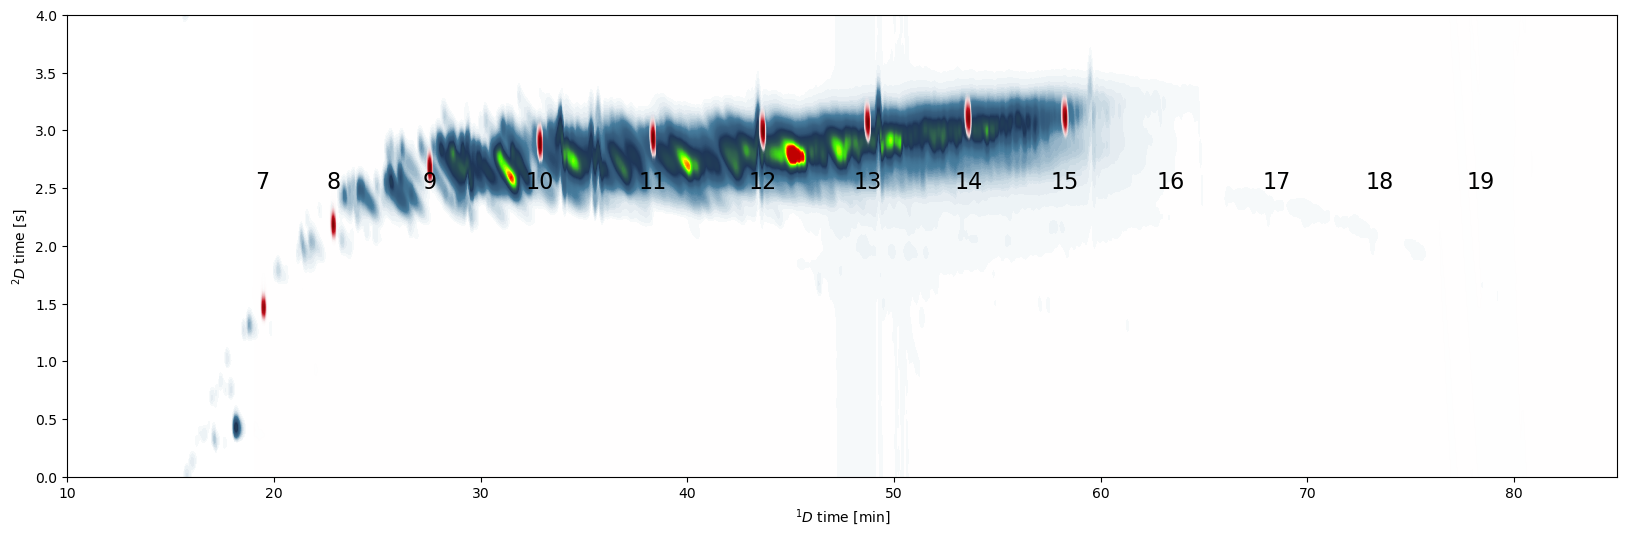

In [14]:
fig, ax = plt.subplots(figsize=(20, 6))

c2c.plot2d(fig, ax, raw_data['RT'].values, raw_data['FID'].values,
           mod_time=4, shift=1.5,
           cbar=False, color_range=(0, 85))
c2c.plot2d(fig, ax, paraffins['RT'].values, paraffins['FID'].values, 
           mod_time=4, shift=1.5, solvent_cut=19,
           cbar=False, color_range=(0, 85),
           cmap=c2c.cmaps.reds)

ax.set_xlim(10, 85)
ax.set_ylim()

# print Carbon Number of Paraffins
for k in lri_calculator.lri_dict.keys():
    ax.text(x=lri_calculator.lri_dict[k], y= 2.5, s=k, fontdict=dict({'fontsize' : 16}),
            ha='center')

plt.show()

### Calculate LRI and add to data frame

In [15]:
results_df['LRI'] = lri_calculator.getLRI_list(results_df['RT 1d (min)'].values)
results_df.head()

,Time,RT 1d (min),RT 2d (s),Height,Time Cluster ID,MS1,Molecule m/z,CNum (m/z) NO,CNum (m/z) Aromates,CNum (m/z) Hydrocarbons,LRI
0,15.775659,15.73,0.02,133.171699,1,53.014:5.84 54.009:10.52 55.055:66.5 57.07:37....,285.279,-1,-1,-1,-1
1,16.043993,16.00,0.12,124.874161,1,53.013:10.66 54.009:8.26 55.055:61.12 57.071:3...,285.280,-1,-1,-1,-1
2,16.581326,16.53,0.36,158.873007,1,53.013:8.69 54.009:8.82 55.054:63.09 57.07:37....,285.280,-1,-1,-1,-1
3,17.113993,17.07,0.32,257.106999,1,53.014:35.22 54.009:8.29 55.029:10.3 55.055:26...,271.264,-1,-1,-1,-1
4,17.580326,17.53,0.30,59.976025,1,55.055:7.0 59.049:100.0,59.049,-1,-1,-1,-1


In [ ]:
# export data frame
results_df.to_csv('sample_data/Flow_C2C-005_results.csv', sep=',', index=False)